<a href="https://colab.research.google.com/github/MCHARD04/CourierFlow/blob/main/COU07506_Week01_240242459097.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 Digital Signal Processing  Week 1: Setting Up the DSP Laboratory

Name: MIHAYO MASANILO RICHARD  
Registration No.: 24024245997
Class: BENG24COE-1
Group: GROUP 9  
Date: 22/11/2026


## Objective

Set up a Python notebook, generate discrete-time signals, read a WAV recording, and prepare a repository for laboratory work.



## Pre-lab
Materials and devices I used today that contain DSP and signal it processes

1. Smartphone microphone processes voice-call audio signal.
2. Bluetooth earphones processes music or speech signal.
3. Wi-Fi router processes radio-frequency data signal.



In [9]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True


## Task 1.1 My first notebook

Generated and plot the unit impulse, unit step, unit ramp, and decaying exponential. The horizontal axis is the discrete sample index n.


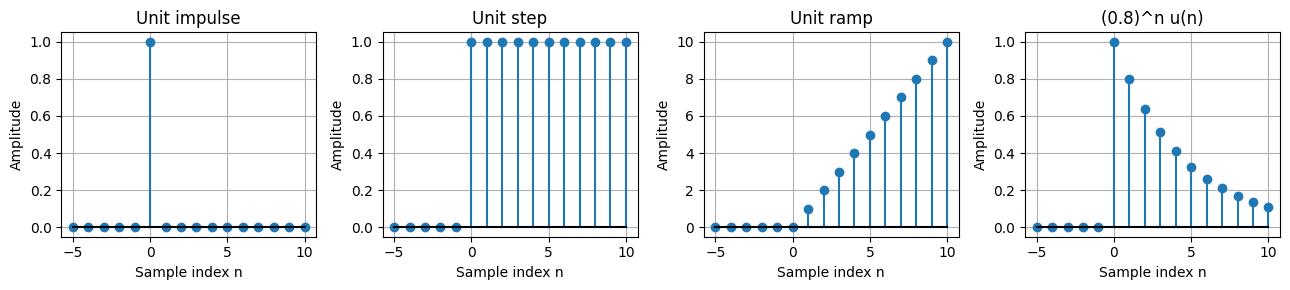

In [10]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = (0.8 ** n) * step

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, values, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Unit impulse", "Unit step", "Unit ramp", "(0.8)^n u(n)"],
):
    ax.stem(n, values, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()


## Task 1.2 Changing the parameters

The first figure plots a^n u(n) for the three required values. The second compares the two discrete-time cosine sequences for n from 0 to 40.


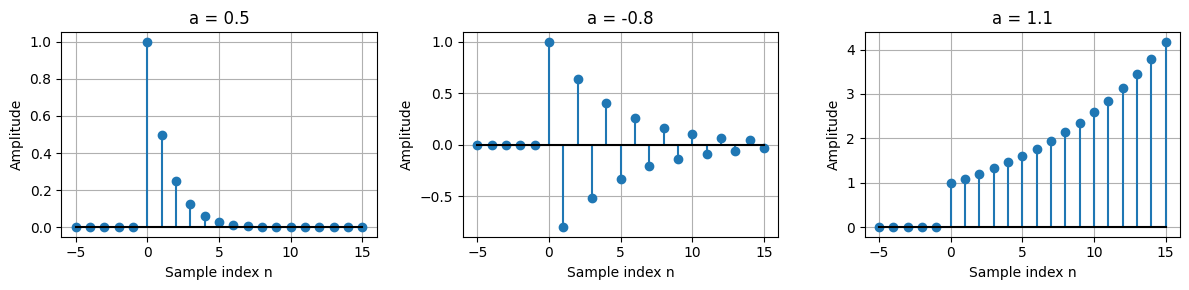

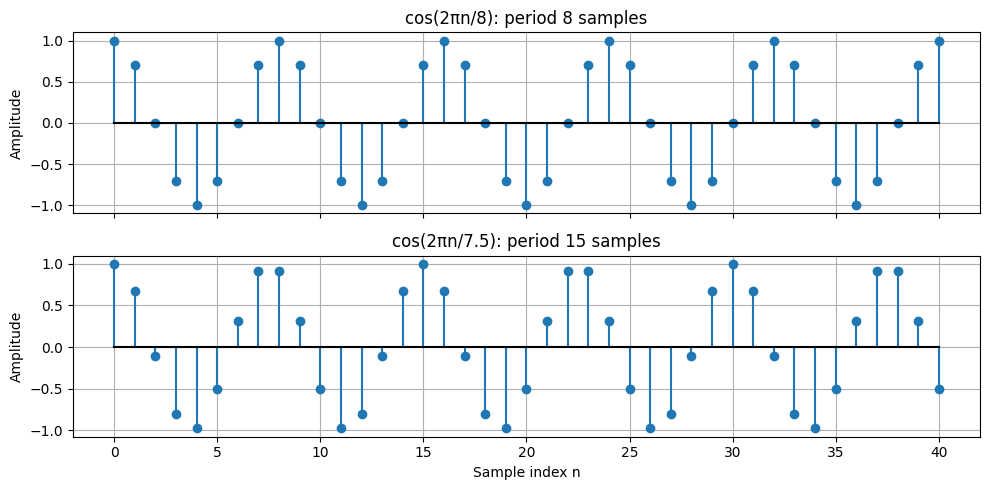

The first sequence repeats every 8 samples.
The second sequence also repeats: 15 / 7.5 = 2 cycles, so its integer period is 15 samples.


In [11]:
n_exp = np.arange(-5, 16)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    values = (a ** n_exp) * (n_exp >= 0)
    ax.stem(n_exp, values, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

n_cos = np.arange(0, 41)
x8 = np.cos(2 * np.pi * n_cos / 8)
x75 = np.cos(2 * np.pi * n_cos / 7.5)
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].stem(n_cos, x8, basefmt="k-")
axes[0].set_title("cos(2πn/8): period 8 samples")
axes[1].stem(n_cos, x75, basefmt="k-")
axes[1].set_title("cos(2πn/7.5): period 15 samples")
axes[1].set_xlabel("Sample index n")
for ax in axes:
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

print("The first sequence repeats every 8 samples.")
print("The second sequence also repeats: 15 / 7.5 = 2 cycles, so its integer period is 15 samples.")


**Task 1.2 result.** Both sequences repeat exactly in discrete time. The first has period 8. Although 7.5 is not an integer, the second sequence completes two cycles in 15 integer samples, so it has period 15. Floating-point plots may show tiny numerical round-off differences.


## Task 1.3  Working with audio

Uploading the voice WAV file to the notebook workspace named my_voice.wav. If it is absent, this cell creates a clearly labelled fallback tone for a code check.


Source: personal voice recording
Sampling rate: 44100 Hz
Duration: 5.00 s
Samples: 220500


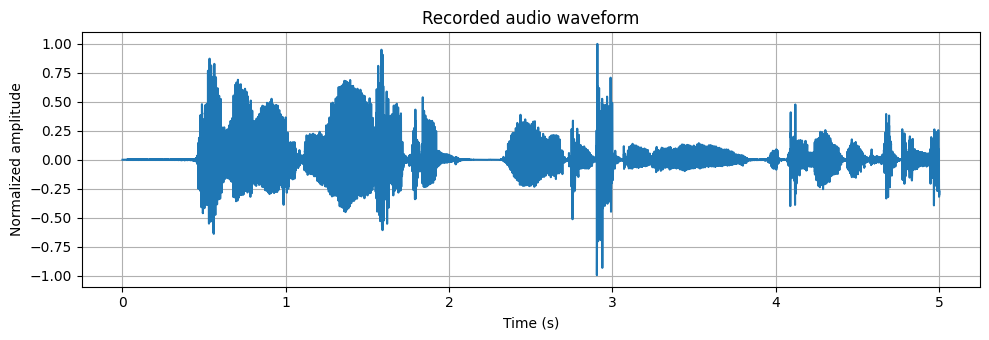

In [12]:

fname = "my_voice.wav"
using_personal_recording = Path(fname).exists()

if using_personal_recording:
    fs, raw = wavfile.read(fname)
    if raw.ndim > 1:
        raw = raw.mean(axis=1)
    x_audio = raw.astype(float)
    peak = np.max(np.abs(x_audio))
    if peak == 0:
        raise ValueError("The WAV recording is silent; please check the file.")
    x_audio = x_audio / peak
    source = "personal voice recording"
else:
    fs = 16000
    t_fallback = np.arange(0, 2, 1 / fs)
    x_audio = 0.5 * np.sin(2 * np.pi * 440 * t_fallback) * np.exp(-t_fallback)
    source = "fallback test signal — replace with my_voice.wav before submission"

t_audio = np.arange(len(x_audio)) / fs
print(f"Source: {source}")
print(f"Sampling rate: {fs} Hz")
print(f"Duration: {len(x_audio) / fs:.2f} s")
print(f"Samples: {len(x_audio)}")

plt.figure(figsize=(10, 3.5))
plt.plot(t_audio, x_audio)
plt.title("Recorded audio waveform")
plt.xlabel("Time (s)")
plt.ylabel("Normalized amplitude")
plt.tight_layout()
plt.show()

display(Audio(x_audio, rate=int(fs)))


## Analysis questions

### 1. Sampling rate and one minute storage

The cell below uses the sampling rate from Task 1.3. A mono recording needs 60 × fs sample values for one minute. Replace the fallback recording with your own WAV before using this result in the final submission.


In [14]:
print(f"Your recording sampling rate: {fs} samples/second")
print(f"Samples needed for one minute of mono audio: {60 * fs:,}")
if not using_personal_recording:
    print("Reminder: this currently describes the fallback signal, not your phone recording.")


Your recording sampling rate: 44100 samples/second
Samples needed for one minute of mono audio: 2,646,000


### 2. Why use a stem plot?

A discrete-time signal is defined only at integer sample indices. A stem plot shows each sample as a separate value and does not imply that the signal has defined values between sample indices. A continuous line can suggest interpolation between samples.

### 3. Stability and the growing exponential

If h[n] = 1.1^n u[n] were an impulse response, it would not be absolutely summable because its samples grow without bound. The corresponding system would violate BIBO stability.


## Conclusion

Complete after running with my recording:
the recording sampling rate: 44100 samples/second
and Samples needed for one minute of mono audio: 2,646,000,  

The four plots show four basic discrete-time signals. The unit impulse is zero everywhere except at n = 0, where its value is 1. The unit step is 0 for negative n and 1 for n ≥ 0. The ramp is 0 for negative n and increases linearly from n = 0. The exponential, (0.8)^n u(n), starts at 1 and decreases toward zero as n increases. Together, the plots show how discrete-time signals are represented by separate samples at integer values of n.

## AI use statement

AI tools used: OpenAI ChatGPT/Codex.  
Used for: preparing explanations and starter code, checking the hand calculations, and organizing the notebook.  
I confirm that I understand and can explain all submitted code.
